In [2]:
!pip install -q nibabel tqdm

In [4]:
import os
import math
import time
import random
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPUS = torch.cuda.device_count()

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("GPUs:", N_GPUS)
for i in range(N_GPUS):
    print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")


PyTorch: 2.10.0+cu128
Device: cuda
GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [5]:
class DepthwiseConv3d(nn.Module):
    def __init__(self, r):
        super().__init__()
        self.r = r
        self.net = None

    def _build(self, c, device):
        self.net = nn.Sequential(
            nn.Conv3d(c, c, kernel_size=self.r, stride=self.r, groups=c, bias=False),
            nn.BatchNorm3d(c),
            nn.ReLU(inplace=True),
            nn.Conv3d(c, c, kernel_size=1, bias=False),
            nn.BatchNorm3d(c),
            nn.ReLU(inplace=True),
        ).to(device)

    def forward(self, x):
        if self.net is None:
            self._build(x.shape[1], x.device)
        return self.net(x)


class TMMM(nn.Module):
    def __init__(self, C, r1, r2):
        super().__init__()
        self.r1, self.r2 = r1, r2
        self.dwconv1 = DepthwiseConv3d(r1)
        self.dwconv2 = DepthwiseConv3d(r2)
        self.norm1 = nn.LayerNorm(C)
        self.norm2 = nn.LayerNorm(C)
        self.act = nn.GELU()

    def forward(self, x):
        b, c, h, w, d = x.shape
        x1 = self.dwconv1(x).permute(0, 2, 3, 4, 1).contiguous().view(b, -1, c)
        x2 = self.dwconv2(x).permute(0, 2, 3, 4, 1).contiguous().view(b, -1, c)
        return self.act(self.norm1(x1)), self.act(self.norm2(x2))


class KVProjection(nn.Module):
    def __init__(self, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.kv_linear = None

    def _build(self, c, device):
        self.kv_linear = nn.Linear(c, c, bias=False).to(device)

    def forward(self, x):
        b, l, c = x.shape
        if self.kv_linear is None:
            self._build(c, x.device)
        x = self.kv_linear(x)
        x = x.view(b, l, self.n_heads, c // self.n_heads).permute(0, 2, 1, 3)
        return torch.chunk(x, 2, dim=1)


class QProjection(nn.Module):
    def __init__(self, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.w_q = None

    def _build(self, c, device):
        self.w_q = nn.Linear(c, c, bias=False).to(device)

    def forward(self, x):
        x = x.permute(0, 2, 3, 4, 1)
        b, h, w, d, c = x.shape
        if self.w_q is None:
            self._build(c, x.device)
        q = self.w_q(x).view(b, h * w * d, self.n_heads, c // self.n_heads).permute(0, 2, 1, 3)
        return torch.chunk(q, 2, dim=1)


class Residual3DBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv3d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv3d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(channels)

    def forward(self, x):
        identity = x
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return self.relu(x + identity)


class Conv1(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.res_block = Residual3DBlock(channels)
        self.pointwise = nn.Sequential(
            nn.Conv3d(channels, channels, 1, bias=False),
            nn.BatchNorm3d(channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.pointwise(self.res_block(x))


class Conv2(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.res_block = Residual3DBlock(channels)

    def forward(self, x):
        return self.res_block(x)


class Embedding3D(nn.Module):
    def __init__(self, in_channels, embed_dim):
        super().__init__()
        self.proj = nn.Conv3d(in_channels, embed_dim, 4, stride=4)
        self.norm = nn.BatchNorm3d(embed_dim)

    def forward(self, x):
        return self.norm(self.proj(x))


class Conv2x2x2(nn.Module):
    def __init__(self, C_in, C_out):
        super().__init__()
        self.conv = nn.Conv3d(C_in, C_out, 2, stride=2)
        self.norm = nn.BatchNorm3d(C_out)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(self.norm(self.conv(x)))


class UpSample3D(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose3d(in_channels, out_channels, 2, stride=2)

    def forward(self, x):
        return self.up(x)


def _attend(module, Q, K, V, C, n_heads):
    b, _, l, _ = V.shape
    s = round(l ** (1 / 3))
    V_3d = V.permute(0, 1, 3, 2).reshape(b, C // 2, s, s, s)
    V_3d = module.conv2(V_3d)
    V = V_3d.view(b, n_heads // 2, C // n_heads, l).permute(0, 1, 3, 2)
    return F.scaled_dot_product_attention(Q, K, V)


def _merge(X1, X2):
    X = torch.cat([X1, X2], dim=1)
    b, h, n, d = X.shape
    s = round(n ** (1 / 3))
    return X.permute(0, 1, 3, 2).reshape(b, h * d, s, s, s)


class TMSM(nn.Module):
    def __init__(self, C, n_heads, r1=4, r2=2):
        super().__init__()
        self.C, self.n_heads = C, n_heads
        self.tmmm = TMMM(C, r1, r2)
        self.q_proj = QProjection(n_heads)
        self.kv_proj1 = KVProjection(n_heads)
        self.kv_proj2 = KVProjection(n_heads)
        self.conv2 = Conv2(C // 2)
        self.conv1 = Conv1(C)

    def forward(self, x):
        I1, I2 = self.tmmm(x)
        Q1, Q2 = self.q_proj(x)
        K1, V1 = self.kv_proj1(I1)
        K2, V2 = self.kv_proj2(I2)
        X1 = _attend(self, Q1, K1, V1, self.C, self.n_heads)
        X2 = _attend(self, Q2, K2, V2, self.C, self.n_heads)
        out = x + _merge(X1, X2)
        identity = out
        return self.conv1(out) + identity


class TMCM(nn.Module):
    def __init__(self, C, n_heads, r1, r2):
        super().__init__()
        self.C, self.n_heads = C, n_heads
        self.q_proj = QProjection(n_heads)
        self.tmmm = TMMM(C, r1, r2)
        self.kv_proj1 = KVProjection(n_heads)
        self.kv_proj2 = KVProjection(n_heads)
        self.conv2 = Conv2(C // 2)
        self.conv1 = Conv1(C)

    def forward(self, Fen, Fde):
        Q1, Q2 = self.q_proj(Fen)
        I1, I2 = self.tmmm(Fde)
        K1, V1 = self.kv_proj1(I1)
        K2, V2 = self.kv_proj2(I2)
        X1 = _attend(self, Q1, K1, V1, self.C, self.n_heads)
        X2 = _attend(self, Q2, K2, V2, self.C, self.n_heads)
        out = Fen + _merge(X1, X2)
        identity = out
        return self.conv1(out) + identity


In [6]:
class EncodingStage1(nn.Module):
    def __init__(self, C, n_heads, r1=4, r2=2):
        super().__init__()
        self.embed = Embedding3D(4, C)
        self.block1 = TMSM(C, n_heads, r1, r2)
        self.block2 = TMSM(C, n_heads, r1, r2)
        self.block3 = TMSM(C, n_heads, r1, r2)

    def forward(self, x):
        x = self.embed(x)
        x = self.block1(x)
        x = self.block2(x)
        return self.block3(x)


class EncodingStage2(nn.Module):
    def __init__(self, C_in, C_out, n_heads, r1, r2):
        super().__init__()
        self.down = Conv2x2x2(C_in, C_out)
        self.block1 = TMSM(C_out, n_heads, r1, r2)
        self.block2 = TMSM(C_out, n_heads, r1, r2)
        self.block3 = TMSM(C_out, n_heads, r1, r2)

    def forward(self, x):
        x = self.down(x)
        x = self.block1(x)
        x = self.block2(x)
        return self.block3(x)


class Encoder(nn.Module):
    def __init__(self, C, n_heads):
        super().__init__()
        self.enc1 = EncodingStage1(C[0], n_heads, 8, 4)
        self.enc2 = EncodingStage2(C[0], C[1], n_heads, 4, 2)
        self.enc3 = EncodingStage2(C[1], C[2], n_heads, 2, 1)
        self.enc4 = EncodingStage2(C[2], C[3], n_heads, 1, 1)

    def forward(self, x):
        Fen1 = self.enc1(x)
        Fen2 = self.enc2(Fen1)
        Fen3 = self.enc3(Fen2)
        Fen4 = self.enc4(Fen3)
        return Fen1, Fen2, Fen3, Fen4


class DecodingStage1(nn.Module):
    def __init__(self, C4, C3, C2, n_heads, r1=4, r2=2):
        super().__init__()
        self.upsample1 = UpSample3D(C4, C3)
        self.upsample2 = UpSample3D(C3, C2)
        self.tmcm = TMCM(C3, n_heads, r1, r2)
        self.block1 = TMSM(C3, n_heads, r1, r2)
        self.block2 = TMSM(C3, n_heads, r1, r2)
        self.block3 = TMSM(C3, n_heads, r1, r2)

    def forward(self, Fen, Fde):
        x = self.upsample1(Fde)
        x = self.tmcm(Fen, x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.upsample2(x)


class DecodingStage2(nn.Module):
    def __init__(self, C2, C1, n_heads, r1=4, r2=2):
        super().__init__()
        self.upsample = UpSample3D(C2, C1)
        self.tmcm = TMCM(C2, n_heads, r1, r2)
        self.block1 = TMSM(C2, n_heads, r1, r2)
        self.block2 = TMSM(C2, n_heads, r1, r2)
        self.block3 = TMSM(C2, n_heads, r1, r2)

    def forward(self, Fen, Fde):
        x = self.tmcm(Fen, Fde)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.upsample(x)


class DecodingStage4(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = Conv1(4)
        self.conv2 = Conv2(4)

    def forward(self, x, Fde):
        return self.conv1(self.conv2(x) + Fde)


class Decoder(nn.Module):
    def __init__(self, C, n_heads):
        super().__init__()
        self.dec1 = DecodingStage1(C[3], C[2], C[1], n_heads, 2, 1)
        self.dec2 = DecodingStage2(C[1], C[0], n_heads, 4, 2)
        self.dec3 = DecodingStage2(C[0], 4, n_heads, 8, 4)
        self.up = UpSample3D(4, 4)
        self.dec4 = DecodingStage4()

    def forward(self, x, Fen1, Fen2, Fen3, Fen4):
        Fde1 = self.dec1(Fen3, Fen4)
        Fde2 = self.dec2(Fen2, Fde1)
        Fde3 = self.dec3(Fen1, Fde2)
        Fde4 = self.dec4(x, self.up(Fde3))
        return Fde1, Fde2, Fde3, Fde4


class SegmentationModel(nn.Module):
    def __init__(self, C=(32, 64, 128, 256), n_heads=16, num_classes=4):
        super().__init__()
        self.encoder = Encoder(C, n_heads)
        self.decoder = Decoder(C, n_heads)
        self.proj1 = nn.Conv3d(64, num_classes, 1)
        self.proj2 = nn.Conv3d(32, num_classes, 1)
        self.proj3 = nn.Conv3d(4, num_classes, 1)
        self.proj4 = nn.Conv3d(4, num_classes, 1)

    def forward(self, x):
        Fen1, Fen2, Fen3, Fen4 = self.encoder(x)
        d1, d2, d3, d4 = self.decoder(x, Fen1, Fen2, Fen3, Fen4)
        return [
            self.proj1(d1),
            self.proj2(d2),
            self.proj3(d3),
            self.proj4(d4),
        ]


In [7]:
def mask_to_onehot(mask, num_classes=4):
    return F.one_hot(mask, num_classes=num_classes).permute(0, 4, 1, 2, 3).float()


def downsample_masks(mask):
    x = mask.unsqueeze(1).float()
    sizes = [(8, 8, 8), (16, 16, 16), (32, 32, 32), (64, 64, 64)]
    return [mask_to_onehot(F.interpolate(x, size=s, mode="nearest").squeeze(1).long()) for s in sizes]


def dice_loss_multiclass(pred, target, smooth=1e-5):
    pred = torch.softmax(pred, dim=1)
    b, c = pred.shape[:2]
    pred = pred.reshape(b, c, -1)
    target = target.reshape(b, c, -1)
    intersection = (pred * target).sum(2)
    denom = pred.square().sum(2) + target.square().sum(2)
    dice = (2 * intersection + smooth) / (denom + smooth)
    return 1 - dice.mean()


DS_WEIGHTS = [0.125, 0.25, 0.5, 1.0]


def deep_supervision_loss(outputs, targets):
    return sum(w * dice_loss_multiclass(p, t) for w, p, t in zip(DS_WEIGHTS, outputs, targets))


def segmentation_metrics(logits, target, num_classes=4, eps=1e-6):
    pred = torch.argmax(logits, dim=1)
    dices, ious = [], []
    for cls in range(num_classes):
        p = pred == cls
        t = target == cls
        tp = (p & t).sum().float()
        fp = (p & ~t).sum().float()
        fn = (~p & t).sum().float()
        dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
        iou = (tp + eps) / (tp + fp + fn + eps)
        dices.append(dice)
        ious.append(iou)

    foreground = target > 0
    pred_foreground = pred > 0
    tp = (pred_foreground & foreground).sum().float()
    fp = (pred_foreground & ~foreground).sum().float()
    fn = (~pred_foreground & foreground).sum().float()
    wt_dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    tc = (target == 1) | (target == 3)
    pred_tc = (pred == 1) | (pred == 3)
    tp = (pred_tc & tc).sum().float()
    fp = (pred_tc & ~tc).sum().float()
    fn = (~pred_tc & tc).sum().float()
    tc_dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    et = target == 3
    pred_et = pred == 3
    tp = (pred_et & et).sum().float()
    fp = (pred_et & ~et).sum().float()
    fn = (~pred_et & et).sum().float()
    et_dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)

    accuracy = (pred == target).float().mean()

    return {
        "dice_bg": dices[0].item(),
        "dice_class1": dices[1].item(),
        "dice_class2": dices[2].item(),
        "dice_class3": dices[3].item(),
        "mean_dice": torch.stack(dices[1:]).mean().item(),
        "mean_iou": torch.stack(ious[1:]).mean().item(),
        "WT_dice": wt_dice.item(),
        "TC_dice": tc_dice.item(),
        "ET_dice": et_dice.item(),
        "accuracy": accuracy.item(),
    }


In [8]:
class BraTSDataset(Dataset):
    def __init__(self, root_dir, target_size=(64, 64, 64)):
        self.root_dir = root_dir
        self.target_size = target_size
        self.patients = sorted(os.listdir(root_dir))
        self.cache = [None] * len(self.patients)

    def __len__(self):
        return len(self.patients)

    def load_nifti(self, path):
        return nib.load(path).get_fdata(dtype=np.float32)

    def normalize(self, x):
        mean = x.mean(axis=(1, 2, 3), keepdims=True)
        std = x.std(axis=(1, 2, 3), keepdims=True)
        return (x - mean) / (std + 1e-8)

    def crop_nonzero(self, image, mask):
        nz = np.where(mask != 0)
        if len(nz[0]) == 0:
            return image, mask
        z0, y0, x0 = np.min(nz, axis=1)
        z1, y1, x1 = np.max(nz, axis=1)
        return image[:, z0:z1+1, y0:y1+1, x0:x1+1], mask[z0:z1+1, y0:y1+1, x0:x1+1]

    def preprocess(self, idx):
        patient = self.patients[idx]
        path = os.path.join(self.root_dir, patient)

        flair = self.load_nifti(os.path.join(path, f"{patient}_flair.nii"))
        t1 = self.load_nifti(os.path.join(path, f"{patient}_t1.nii"))
        t1ce = self.load_nifti(os.path.join(path, f"{patient}_t1ce.nii"))
        t2 = self.load_nifti(os.path.join(path, f"{patient}_t2.nii"))
        seg = self.load_nifti(os.path.join(path, f"{patient}_seg.nii")).astype(np.int64)

        seg[seg == 4] = 3
        image = np.stack([flair, t1, t1ce, t2])
        image, seg = self.crop_nonzero(image, seg)
        image = self.normalize(image)

        image = torch.from_numpy(image).unsqueeze(0)
        image = F.interpolate(image, size=self.target_size, mode="trilinear", align_corners=False).squeeze(0)

        seg = torch.from_numpy(seg).unsqueeze(0).unsqueeze(0).float()
        seg = F.interpolate(seg, size=self.target_size, mode="nearest").squeeze().long()

        return image.contiguous(), seg.contiguous()

    def __getitem__(self, idx):
        if self.cache[idx] is None:
            self.cache[idx] = self.preprocess(idx)
        return self.cache[idx]


ROOT = "/kaggle/input/datasets/aryashah2k/brain-tumor-segmentation-brats-2019/MICCAI_BraTS_2019_Data_Training/HGG"
dataset = BraTSDataset(ROOT)

print("Patients:", len(dataset))
print("Preloading processed volumes...")
for i in tqdm(range(len(dataset)), desc="Preload"):
    _ = dataset[i]
print("Preload complete.")


Patients: 259
Preloading processed volumes...


Preload:   0%|          | 0/259 [00:00<?, ?it/s]

Preload complete.


In [9]:
val_fraction = 0.2
n_val = max(1, int(len(dataset) * val_fraction))
n_train = len(dataset) - n_val

generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(dataset, [n_train, n_val], generator=generator)

print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")


Train: 208
Validation: 51


In [10]:
class SegmentationPipeline:
    def __init__(self, C=(32, 64, 128, 256), n_heads=16, num_classes=4,
                 lr=1e-4, epochs=5, batch_size=16, num_workers=4):
        self.C = C
        self.n_heads = n_heads
        self.num_classes = num_classes
        self.lr = lr
        self.epochs = epochs
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.device = DEVICE
        self.model_ = None
        self.history = []

    def _build(self, sample_shape):
        model = SegmentationModel(self.C, self.n_heads, self.num_classes).to(self.device)

        # Build lazy projection layers BEFORE creating the optimizer.
        with torch.no_grad():
            dummy = torch.zeros(sample_shape, device=self.device)
            _ = model(dummy)

        if N_GPUS > 1:
            model = nn.DataParallel(model)

        self.model_ = model

    def _make_loader(self, dataset, shuffle):
        kwargs = dict(
            batch_size=self.batch_size,
            shuffle=shuffle,
            num_workers=self.num_workers,
            pin_memory=True,
            drop_last=shuffle,
        )
        if self.num_workers > 0:
            kwargs["persistent_workers"] = True
            kwargs["prefetch_factor"] = 2
        return DataLoader(dataset, **kwargs)

    @staticmethod
    def _accumulate(store, metrics, weight):
        for k, v in metrics.items():
            store[k] = store.get(k, 0.0) + v * weight

    @staticmethod
    def _average(store, total):
        return {k: v / total for k, v in store.items()}

    def train(self, train_dataset, val_dataset):
        sample, _ = train_dataset[0]
        self._build((1, *sample.shape))

        train_loader = self._make_loader(train_dataset, True)
        val_loader = self._make_loader(val_dataset, False)

        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=1e-5)
        scaler = torch.amp.GradScaler("cuda", enabled=self.device.type == "cuda")

        print(f"Training with {N_GPUS} GPU(s), global batch size {self.batch_size}")
        if N_GPUS > 1:
            print("DataParallel is active.")

        for epoch in range(self.epochs):
            start = time.perf_counter()
            self.model_.train()
            train_stats = {}
            train_samples = 0
            running_loss = 0.0

            progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{self.epochs}", unit="batch")
            for step, (image, seg) in enumerate(progress):
                image = image.to(self.device, non_blocking=True)
                seg = seg.to(self.device, non_blocking=True)

                optimizer.zero_grad(set_to_none=True)

                with torch.autocast(device_type=self.device.type, dtype=torch.float16,
                                    enabled=self.device.type == "cuda"):
                    outputs = self.model_(image)
                    targets = downsample_masks(seg)
                    loss = deep_supervision_loss(outputs, targets)

                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

                bs = image.size(0)
                running_loss += loss.item() * bs
                train_samples += bs

                with torch.no_grad():
                    m = segmentation_metrics(outputs[-1].float(), seg, self.num_classes)
                self._accumulate(train_stats, m, bs)

                progress.set_postfix(
                    loss=f"{running_loss/train_samples:.4f}",
                    dice=f"{train_stats['mean_dice']/train_samples:.4f}"
                )

            train_stats = self._average(train_stats, train_samples)
            train_loss = running_loss / train_samples

            self.model_.eval()
            val_stats = {}
            val_loss_sum = 0.0
            val_samples = 0

            with torch.inference_mode():
                for image, seg in val_loader:
                    image = image.to(self.device, non_blocking=True)
                    seg = seg.to(self.device, non_blocking=True)

                    with torch.autocast(device_type=self.device.type, dtype=torch.float16,
                                        enabled=self.device.type == "cuda"):
                        outputs = self.model_(image)
                        targets = downsample_masks(seg)
                        loss = deep_supervision_loss(outputs, targets)

                    bs = image.size(0)
                    val_loss_sum += loss.item() * bs
                    val_samples += bs
                    m = segmentation_metrics(outputs[-1].float(), seg, self.num_classes)
                    self._accumulate(val_stats, m, bs)

            val_stats = self._average(val_stats, val_samples)
            val_loss = val_loss_sum / val_samples
            epoch_time = time.perf_counter() - start

            row = {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "train_mean_dice": train_stats["mean_dice"],
                "val_mean_dice": val_stats["mean_dice"],
                "train_mean_iou": train_stats["mean_iou"],
                "val_mean_iou": val_stats["mean_iou"],
                "val_WT_dice": val_stats["WT_dice"],
                "val_TC_dice": val_stats["TC_dice"],
                "val_ET_dice": val_stats["ET_dice"],
                "val_accuracy": val_stats["accuracy"],
                "epoch_seconds": epoch_time,
            }
            self.history.append(row)

            print(
                f"Epoch {epoch+1}: "
                f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
                f"train_Dice={train_stats['mean_dice']:.4f} | "
                f"val_Dice={val_stats['mean_dice']:.4f} | "
                f"val_IoU={val_stats['mean_iou']:.4f} | "
                f"WT={val_stats['WT_dice']:.4f} | "
                f"TC={val_stats['TC_dice']:.4f} | "
                f"ET={val_stats['ET_dice']:.4f} | "
                f"time={epoch_time:.1f}s"
            )

        return self

    def predict(self, image):
        if image.dim() == 4:
            image = image.unsqueeze(0)
        image = image.to(self.device, non_blocking=True)
        self.model_.eval()
        with torch.inference_mode(), torch.autocast(
            device_type=self.device.type, dtype=torch.float16,
            enabled=self.device.type == "cuda"
        ):
            outputs = self.model_(image)
        return torch.argmax(outputs[-1], dim=1)

    def save(self, path):
        model = self.model_.module if isinstance(self.model_, nn.DataParallel) else self.model_
        torch.save(model.state_dict(), path)

    def load(self, path):
        if self.model_ is None:
            sample, _ = dataset[0]
            self._build((1, *sample.shape))
        model = self.model_.module if isinstance(self.model_, nn.DataParallel) else self.model_
        model.load_state_dict(torch.load(path, map_location=self.device))
        return self


In [11]:
pipeline = SegmentationPipeline(
    C=(32, 64, 128, 256),
    n_heads=16,
    num_classes=4,
    lr=1e-4,
    epochs=200,
    batch_size=32,
    num_workers=4,
)

pipeline.train(train_dataset, val_dataset)

Training with 2 GPU(s), global batch size 32
DataParallel is active.


Epoch 1/200:   0%|          | 0/6 [00:00<?, ?batch/s]

Epoch 1: train_loss=1.3172 | val_loss=1.2864 | train_Dice=0.1428 | val_Dice=0.1750 | val_IoU=0.1164 | WT=0.4107 | TC=0.0293 | ET=0.0183 | time=16.1s


Epoch 2/200:   0%|          | 0/6 [00:00<?, ?batch/s]

Epoch 2: train_loss=1.2696 | val_loss=1.2570 | train_Dice=0.1510 | val_Dice=0.1846 | val_IoU=0.1240 | WT=0.4306 | TC=0.0386 | ET=0.0264 | time=11.8s


Epoch 3/200:   0%|          | 0/6 [00:00<?, ?batch/s]

... (391 outputs left out)

Epoch 199/200:   0%|          | 0/6 [00:00<?, ?batch/s]

Epoch 199: train_loss=0.4771 | val_loss=0.6881 | train_Dice=0.8218 | val_Dice=0.6177 | val_IoU=0.4547 | WT=0.7557 | TC=0.7289 | ET=0.6915 | time=12.0s


Epoch 200/200:   0%|          | 0/6 [00:00<?, ?batch/s]

Epoch 200: train_loss=0.4743 | val_loss=0.6847 | train_Dice=0.8220 | val_Dice=0.6313 | val_IoU=0.4680 | WT=0.7618 | TC=0.7447 | ET=0.7033 | time=12.0s


,epoch,train_loss,val_loss,train_mean_dice,val_mean_dice,train_mean_iou,val_mean_iou,val_WT_dice,val_TC_dice,val_ET_dice,val_accuracy,epoch_seconds
0,1,1.317173,1.286402,0.142805,0.174972,0.087626,0.116428,0.410728,0.029344,0.018344,0.155749,16.082511
1,2,1.269557,1.256991,0.151006,0.184559,0.094370,0.124020,0.430632,0.038582,0.026409,0.238150,11.807334
2,3,1.239015,1.230819,0.156588,0.186715,0.098922,0.125042,0.462805,0.044630,0.033474,0.351486,11.608234
3,4,1.210879,1.211030,0.164270,0.187355,0.105490,0.125282,0.464018,0.046933,0.036105,0.361293,11.843973
4,5,1.187807,1.190927,0.172968,0.189659,0.112841,0.127181,0.465258,0.048866,0.037908,0.362523,11.789592
...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,0.482548,0.687660,0.818266,0.624829,0.693049,0.463847,0.774445,0.739324,0.706231,0.820992,11.870694
196,197,0.480892,0.677615,0.818262,0.627993,0.693377,0.464406,0.759671,0.743028,0.698207,0.807051,12.082919
197,198,0.480832,0.682182,0.820038,0.631240,0.695584,0.468538,0.765309,0.746634,0.705803,0.812953,12.074699
198,199,0.477074,0.688116,0.821791,0.617701,0.698110,0.454737,0.755685,0.728936,0.691528,0.804151,11.980389


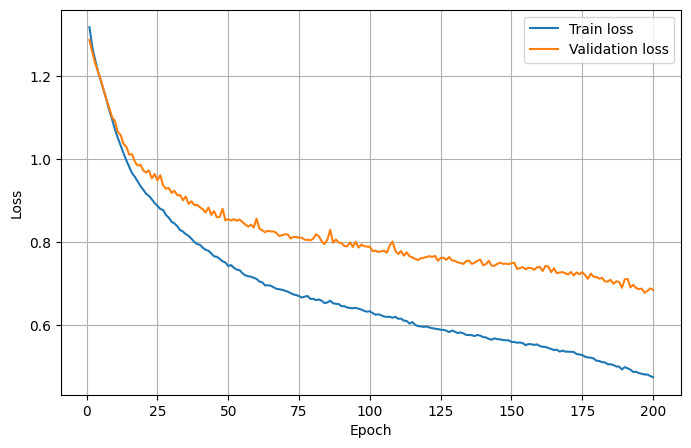

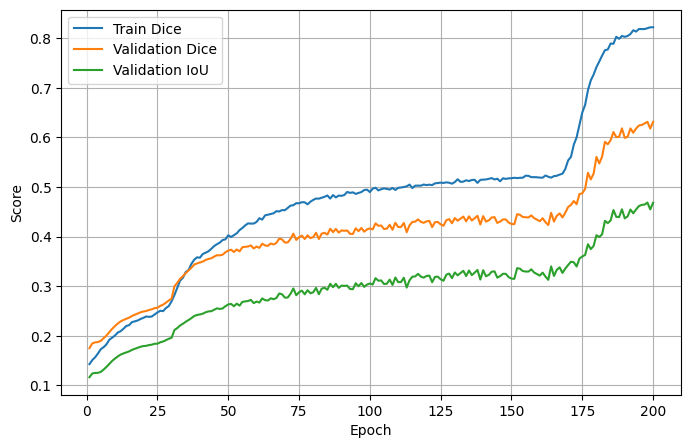

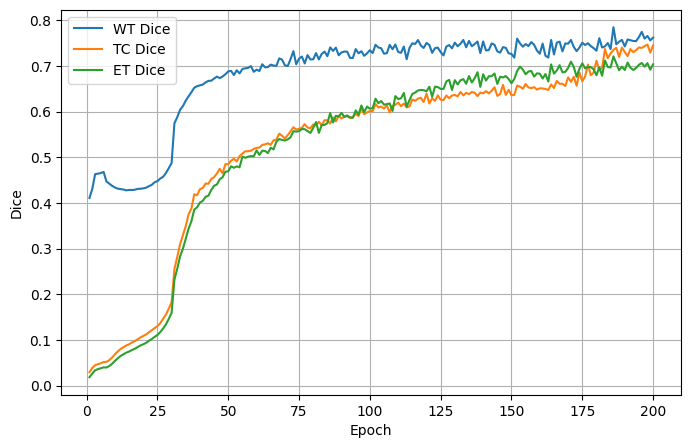

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

history = pd.DataFrame(pipeline.history)
display(history)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["epoch"], history["train_loss"], label="Train loss")
ax.plot(history["epoch"], history["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["epoch"], history["train_mean_dice"], label="Train Dice")
ax.plot(history["epoch"], history["val_mean_dice"], label="Validation Dice")
ax.plot(history["epoch"], history["val_mean_iou"], label="Validation IoU")
ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.legend()
ax.grid(True)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["epoch"], history["val_WT_dice"], label="WT Dice")
ax.plot(history["epoch"], history["val_TC_dice"], label="TC Dice")
ax.plot(history["epoch"], history["val_ET_dice"], label="ET Dice")
ax.set_xlabel("Epoch")
ax.set_ylabel("Dice")
ax.legend()
ax.grid(True)
plt.show()


In [13]:
pipeline.save("segmentation_model.pt")

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(
            f"GPU {i}: peak allocated "
            f"{torch.cuda.max_memory_allocated(i)/1024**3:.2f} GB"
        )


GPU 0: peak allocated 6.88 GB
GPU 1: peak allocated 6.43 GB


In [14]:
image, seg = dataset[5]
pred = pipeline.predict(image)

print("Prediction shape:", pred.shape)

data = pred[0].cpu().numpy()

def plot_slice(slice_idx):
    plt.figure(figsize=(6, 6))
    plt.imshow(data[slice_idx], cmap="gray")
    plt.title(f"Prediction - Slice {slice_idx}")
    plt.axis("off")
    plt.show()

from ipywidgets import interact, IntSlider

interact(
    plot_slice,
    slice_idx=IntSlider(
        min=0,
        max=data.shape[0] - 1,
        step=1,
        value=data.shape[0] // 2,
        description="Slice:"
    )
)


Prediction shape: torch.Size([1, 64, 64, 64])


interactive(children=(IntSlider(value=32, description='Slice:', max=63), Output()), _dom_classes=('widget-inte…

<function __main__.plot_slice(slice_idx)>

In [ ]:
import copy


class OptimizedInference:
    """GPU-optimized inference on a single GPU (no DataParallel scatter/gather):
    pure FP16 weights + activations (tensor cores), eval-mode BatchNorm, grads
    disabled, cuDNN autotune, optional torch.compile with eager fallback,
    pinned-memory async transfers and batched execution."""

    def __init__(self, model, device=DEVICE, half=True, compile_model=True):
        model = model.module if isinstance(model, nn.DataParallel) else model
        self.device = device
        self.dtype = torch.float16 if (half and device.type == "cuda") else torch.float32

        m = copy.deepcopy(model).to(device).eval().to(self.dtype)
        for p in m.parameters():
            p.requires_grad_(False)

        self.eager = m
        self.model = m
        if compile_model and device.type == "cuda" and hasattr(torch, "compile"):
            try:
                self.model = torch.compile(m)
            except Exception as e:
                print("torch.compile unavailable, using eager:", e)

    def _prep(self, x):
        return x.to(self.device, non_blocking=True).to(self.dtype)

    @torch.inference_mode()
    def _forward(self, x):
        try:
            out = self.model(x)
        except Exception as e:  # compile failure -> fall back to eager
            print("Compiled model failed, falling back to eager:", repr(e)[:200])
            self.model = self.eager
            out = self.model(x)
        return torch.argmax(out[-1], dim=1)

    @torch.inference_mode()
    def predict(self, volumes):
        if volumes.dim() == 4:
            volumes = volumes.unsqueeze(0)
        return self._forward(self._prep(volumes))

    @torch.inference_mode()
    def benchmark(self, volumes, batch_size=8, repeats=5, warmup=3):
        """volumes: CPU tensor [N, 4, D, H, W]. Returns ms/volume and volumes/s."""
        if self.device.type == "cuda":
            volumes = volumes.pin_memory()
        for _ in range(warmup):                      # cuDNN autotune / compile
            self._forward(self._prep(volumes[:batch_size]))
        times = []
        for _ in range(repeats):
            if self.device.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
            for i in range(0, len(volumes), batch_size):
                self._forward(self._prep(volumes[i:i + batch_size]))
            if self.device.type == "cuda":
                torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
        best = min(times)
        return {"ms_per_volume": best / len(volumes) * 1000,
                "volumes_per_s": len(volumes) / best}


@torch.inference_mode()
def benchmark_cpu(model, volumes):
    model = model.module if isinstance(model, nn.DataParallel) else model
    cpu_model = copy.deepcopy(model).float().cpu().eval()
    cpu_model(volumes[:1].float())  # warmup
    t0 = time.perf_counter()
    for i in range(len(volumes)):
        cpu_model(volumes[i:i + 1].float())
    dt = time.perf_counter() - t0
    return {"ms_per_volume": dt / len(volumes) * 1000,
            "volumes_per_s": len(volumes) / dt}


# ---- Benchmark on validation volumes ----
N_BENCH = min(32, len(val_dataset))
volumes = torch.stack([val_dataset[i][0] for i in range(N_BENCH)])

cpu_res = benchmark_cpu(pipeline.model_, volumes[:min(8, N_BENCH)])
print(f"CPU baseline : {cpu_res['ms_per_volume']:.1f} ms/volume "
      f"({cpu_res['volumes_per_s']:.2f} volumes/s)")

if torch.cuda.is_available():
    fast = OptimizedInference(pipeline.model_)
    gpu_res = fast.benchmark(volumes, batch_size=8)
    speedup = cpu_res["ms_per_volume"] / gpu_res["ms_per_volume"]
    print(f"Optimized GPU: {gpu_res['ms_per_volume']:.1f} ms/volume "
          f"({gpu_res['volumes_per_s']:.2f} volumes/s)")
    print(f"Speedup over CPU: {speedup:.2f}x")

    # Sanity check: optimized predictions agree with the original pipeline
    ref = torch.cat([pipeline.predict(v) for v in volumes[:4]])
    opt = fast.predict(volumes[:4])
    print(f"Agreement with original pipeline: {(ref == opt).float().mean().item()*100:.2f}%")
else:
    print("No CUDA device available - GPU benchmark skipped.")
